# Sistem Basis Data Perpustakaan
SQLite dan Analisis Data dengan pandas

**Nama:** Muhamad Faisal  
**NIM:** 411251167

## Soal 1 — Membuat tiga tabel
Membuat tabel `buku`, `anggota`, dan `peminjaman`. Tanggal menggunakan format YYYY-MM-DD. Sel ini mengatur ulang tabel contoh saat dijalankan ulang.

In [1]:
# SOAL 1 — Persiapan database dan pembuatan tabel
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

conn = sqlite3.connect("perpustakaan.db")
conn.execute("PRAGMA foreign_keys = ON;")

conn.executescript("""
DROP TABLE IF EXISTS peminjaman;
DROP TABLE IF EXISTS anggota;
DROP TABLE IF EXISTS buku;

CREATE TABLE buku (
    id INTEGER PRIMARY KEY,
    judul TEXT NOT NULL,
    penulis TEXT NOT NULL,
    tahun INTEGER NOT NULL
);
CREATE TABLE anggota (
    id INTEGER PRIMARY KEY,
    nama TEXT NOT NULL,
    email TEXT NOT NULL UNIQUE
);
CREATE TABLE peminjaman (
    id INTEGER PRIMARY KEY,
    id_anggota INTEGER NOT NULL,
    id_buku INTEGER NOT NULL,
    tgl_pinjam TEXT NOT NULL,
    tgl_kembali TEXT,
    FOREIGN KEY (id_anggota) REFERENCES anggota(id),
    FOREIGN KEY (id_buku) REFERENCES buku(id)
);
""")
print("Database dan tiga tabel berhasil dibuat.")

Database dan tiga tabel berhasil dibuat.


## Soal 1a — Menambahkan 5 buku dan 3 anggota

In [2]:
# SOAL 1a — Menambahkan data buku dan anggota
data_buku = [
    (1, "Dasar-Dasar Python", "Andi Pratama", 2022),
    (2, "Belajar Basis Data", "Siti Rahma", 2021),
    (3, "Pengantar Analisis Data", "Budi Santoso", 2023),
    (4, "Statistika untuk Pemula", "Dewi Lestari", 2020),
    (5, "Visualisasi Data Praktis", "Rina Wulandari", 2024)
]
data_anggota = [
    (1, "Alya", "alya@example.com"),
    (2, "Bima", "bima@example.com"),
    (3, "Citra", "citra@example.com")
]
with conn:
    conn.executemany(
        "INSERT INTO buku (id, judul, penulis, tahun) VALUES (?, ?, ?, ?)",
        data_buku
    )
    conn.executemany(
        "INSERT INTO anggota (id, nama, email) VALUES (?, ?, ?)",
        data_anggota
    )
print("Data buku:")
display(pd.read_sql_query("SELECT * FROM buku", conn))
print("Data anggota:")
display(pd.read_sql_query("SELECT * FROM anggota", conn))

Data buku:


,id,judul,penulis,tahun
0,1,Dasar-Dasar Python,Andi Pratama,2022
1,2,Belajar Basis Data,Siti Rahma,2021
2,3,Pengantar Analisis Data,Budi Santoso,2023
3,4,Statistika untuk Pemula,Dewi Lestari,2020
4,5,Visualisasi Data Praktis,Rina Wulandari,2024


Data anggota:


,id,nama,email
0,1,Alya,alya@example.com
1,2,Bima,bima@example.com
2,3,Citra,citra@example.com


## Soal 1b — Menambahkan 4 transaksi peminjaman
`None` dalam Python disimpan sebagai `NULL` di SQLite, yang menandakan buku belum dikembalikan.

In [3]:
# SOAL 1b — Menambahkan transaksi peminjaman
data_peminjaman = [
    (1, 1, 1, "2026-11-01", "2026-11-08"),
    (2, 2, 2, "2026-11-03", "2026-11-13"),
    (3, 1, 3, "2026-11-10", "2026-11-17"),
    (4, 3, 4, "2026-11-18", None)
]
with conn:
    conn.executemany("""
        INSERT INTO peminjaman
        (id, id_anggota, id_buku, tgl_pinjam, tgl_kembali)
        VALUES (?, ?, ?, ?, ?)
    """, data_peminjaman)
display(pd.read_sql_query("SELECT * FROM peminjaman", conn))
jumlah_belum = conn.execute(
    "SELECT COUNT(*) FROM peminjaman WHERE tgl_kembali IS NULL"
).fetchone()[0]
print("Peminjaman belum dikembalikan:", jumlah_belum)

,id,id_anggota,id_buku,tgl_pinjam,tgl_kembali
0,1,1,1,2026-11-01,2026-11-08
1,2,2,2,2026-11-03,2026-11-13
2,3,1,3,2026-11-10,2026-11-17
3,4,3,4,2026-11-18,None


Peminjaman belum dikembalikan: 1


## Soal 1c — Daftar peminjaman lengkap menggunakan JOIN
Menggabungkan transaksi dengan nama anggota dan judul buku.

In [4]:
# SOAL 1c — Query JOIN
query_peminjaman = """
SELECT p.id AS id_peminjaman,
       a.nama AS nama_anggota,
       b.judul AS judul_buku,
       p.tgl_pinjam,
       p.tgl_kembali
FROM peminjaman AS p
JOIN anggota AS a ON p.id_anggota = a.id
JOIN buku AS b ON p.id_buku = b.id
ORDER BY p.id;
"""
cursor = conn.execute(query_peminjaman)
print(" | ".join(kolom[0] for kolom in cursor.description))
for baris in cursor.fetchall():
    print(" | ".join("NULL" if nilai is None else str(nilai) for nilai in baris))

id_peminjaman | nama_anggota | judul_buku | tgl_pinjam | tgl_kembali
1 | Alya | Dasar-Dasar Python | 2026-11-01 | 2026-11-08
2 | Bima | Belajar Basis Data | 2026-11-03 | 2026-11-13
3 | Alya | Pengantar Analisis Data | 2026-11-10 | 2026-11-17
4 | Citra | Statistika untuk Pemula | 2026-11-18 | NULL


## Soal 1d — Jumlah peminjaman per anggota menggunakan GROUP BY
`COUNT(p.id)` menghitung seluruh transaksi, termasuk yang sudah dikembalikan. `LEFT JOIN` juga menampilkan anggota tanpa transaksi dengan jumlah 0.

In [5]:
# SOAL 1d — GROUP BY dan fungsi agregasi COUNT
query_jumlah = """
SELECT a.id AS id_anggota,
       a.nama AS nama_anggota,
       COUNT(p.id) AS jumlah_buku_dipinjam
FROM anggota AS a
LEFT JOIN peminjaman AS p ON a.id = p.id_anggota
GROUP BY a.id, a.nama
ORDER BY jumlah_buku_dipinjam DESC, a.nama;
"""
for id_anggota, nama, jumlah in conn.execute(query_jumlah).fetchall():
    print(f"{nama}: {jumlah} peminjaman")

Alya: 2 peminjaman
Bima: 1 peminjaman
Citra: 1 peminjaman


## Soal 2a — Membuat DataFrame pandas dari query SQL
Menggunakan query JOIN dari soal 1c dan query agregasi dari soal 1d.

In [6]:
# SOAL 2a — Membuat DataFrame dari hasil query SQL
df_peminjaman = pd.read_sql_query(query_peminjaman, conn)
df_jumlah = pd.read_sql_query(query_jumlah, conn)
print("DataFrame daftar peminjaman:")
display(df_peminjaman)
print("DataFrame jumlah peminjaman per anggota:")
display(df_jumlah)

DataFrame daftar peminjaman:


,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali
0,1,Alya,Dasar-Dasar Python,2026-11-01,2026-11-08
1,2,Bima,Belajar Basis Data,2026-11-03,2026-11-13
2,3,Alya,Pengantar Analisis Data,2026-11-10,2026-11-17
3,4,Citra,Statistika untuk Pemula,2026-11-18,None


DataFrame jumlah peminjaman per anggota:


,id_anggota,nama_anggota,jumlah_buku_dipinjam
0,1,Alya,2
1,2,Bima,1
2,3,Citra,1


## Soal 2b — Eksplorasi data dan durasi peminjaman
Durasi final hanya dihitung untuk buku yang sudah kembali. Untuk buku yang belum kembali, lama peminjaman berjalan dihitung secara terpisah sampai tanggal acuan **25 November 2026**, agar hasil analisis dapat direproduksi.

In [7]:
# SOAL 2b — Menghitung durasi dan mengeksplorasi pola
df_peminjaman["tgl_pinjam"] = pd.to_datetime(df_peminjaman["tgl_pinjam"])
df_peminjaman["tgl_kembali"] = pd.to_datetime(df_peminjaman["tgl_kembali"])
belum_kembali = df_peminjaman["tgl_kembali"].isna()
df_peminjaman["status"] = belum_kembali.map({
    True: "Belum dikembalikan",
    False: "Sudah dikembalikan"
})
df_peminjaman["durasi_hari"] = (
    df_peminjaman["tgl_kembali"] - df_peminjaman["tgl_pinjam"]
).dt.days.astype("Int64")

tanggal_acuan = pd.Timestamp("2026-11-25")
df_peminjaman["lama_berjalan_hari"] = (
    (tanggal_acuan - df_peminjaman["tgl_pinjam"])
    .dt.days.where(belum_kembali).astype("Int64")
)
display(df_peminjaman)

durasi_selesai = df_peminjaman["durasi_hari"].dropna()
print("Total transaksi:", len(df_peminjaman))
print("Sudah dikembalikan:", int((~belum_kembali).sum()))
print("Belum dikembalikan:", int(belum_kembali.sum()))
print(f"Rata-rata durasi peminjaman selesai: {durasi_selesai.mean():.1f} hari")
jumlah_tertinggi = df_jumlah["jumlah_buku_dipinjam"].max()
anggota_teraktif = df_jumlah.loc[
    df_jumlah["jumlah_buku_dipinjam"] == jumlah_tertinggi, "nama_anggota"
].tolist()
print("Anggota paling aktif:", ", ".join(anggota_teraktif))

,id_peminjaman,nama_anggota,judul_buku,tgl_pinjam,tgl_kembali,status,durasi_hari,lama_berjalan_hari
0,1,Alya,Dasar-Dasar Python,2026-11-01,2026-11-08,Sudah dikembalikan,7,<NA>
1,2,Bima,Belajar Basis Data,2026-11-03,2026-11-13,Sudah dikembalikan,10,<NA>
2,3,Alya,Pengantar Analisis Data,2026-11-10,2026-11-17,Sudah dikembalikan,7,<NA>
3,4,Citra,Statistika untuk Pemula,2026-11-18,NaT,Belum dikembalikan,<NA>,7


Total transaksi: 4
Sudah dikembalikan: 3
Belum dikembalikan: 1
Rata-rata durasi peminjaman selesai: 8.0 hari
Anggota paling aktif: Alya


## Soal 2c — Visualisasi menggunakan matplotlib
Diagram batang membandingkan jumlah transaksi per anggota. Histogram menunjukkan distribusi durasi peminjaman yang sudah selesai; peminjaman yang belum kembali tidak masuk histogram.

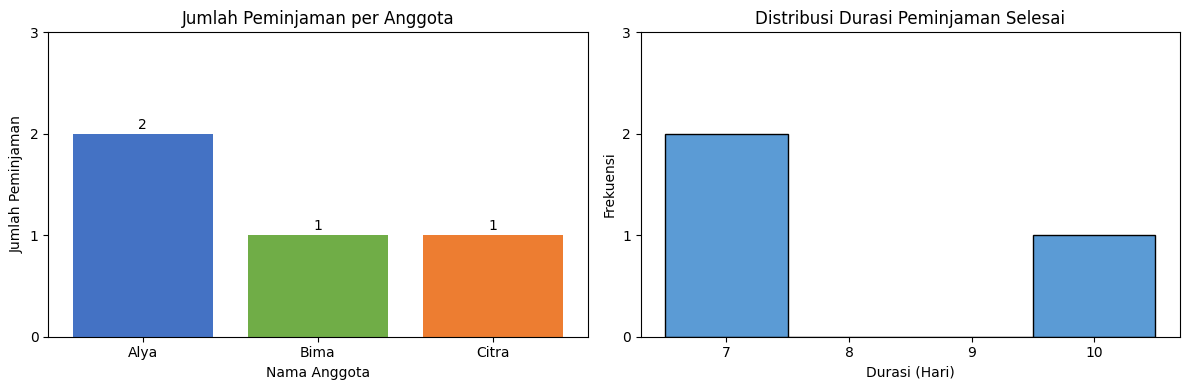

In [8]:
# SOAL 2c — Diagram batang dan histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bars = axes[0].bar(
    df_jumlah["nama_anggota"],
    df_jumlah["jumlah_buku_dipinjam"],
    color=["#4472C4", "#70AD47", "#ED7D31"]
)
axes[0].set_title("Jumlah Peminjaman per Anggota")
axes[0].set_xlabel("Nama Anggota")
axes[0].set_ylabel("Jumlah Peminjaman")
axes[0].set_ylim(0, jumlah_tertinggi + 1)
axes[0].set_yticks(range(int(jumlah_tertinggi) + 2))
for bar in bars:
    tinggi = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        tinggi + 0.05, str(int(tinggi)), ha="center"
    )

durasi_plot = durasi_selesai.astype(int)
batas_interval = [
    nilai - 0.5 for nilai in
    range(int(durasi_plot.min()), int(durasi_plot.max()) + 2)
]
axes[1].hist(durasi_plot, bins=batas_interval,
             color="#5B9BD5", edgecolor="black")
axes[1].set_title("Distribusi Durasi Peminjaman Selesai")
axes[1].set_xlabel("Durasi (Hari)")
axes[1].set_ylabel("Frekuensi")
axes[1].set_xticks(range(int(durasi_plot.min()), int(durasi_plot.max()) + 1))
axes[1].set_yticks(range(len(durasi_plot) + 1))
plt.tight_layout()
plt.show()

## Kesimpulan
- Terdapat 5 buku, 3 anggota, dan 4 transaksi peminjaman.
- Alya melakukan 2 peminjaman; Bima dan Citra masing-masing 1 peminjaman.
- Tiga peminjaman telah selesai, dengan durasi 7, 10, dan 7 hari; rata-rata 8 hari.
- Satu peminjaman belum dikembalikan, yaitu oleh Citra; lama berjalan 7 hari per 25 November 2026.
- Data contoh masih terlalu sedikit untuk menyimpulkan pola umum.
